In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [4]:
# Load
df = pd.read_csv(r"C:\\Users\\acer\\OneDrive\\Desktop\\WeeklyTask\house sales.csv")

# =========================================================
# 9. House Sales - Data Cleaning & Feature Engineering
# =========================================================

In [5]:
# 1. Cleaning
print("Original:", df.shape)
print(df.isnull().sum())


Original: (21613, 21)
id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64


In [6]:
# date preprocessing -> datetime -> year, month
df['date'] = pd.to_datetime(df['date'])
df['sale_year'] = df['date'].dt.year
df['sale_month'] = df['date'].dt.month
df['sale_day'] = df['date'].dt.day

In [7]:
# location attributes
df['zipcode'] = df['zipcode'].astype(str)


In [8]:
# Remove outliers / errors (common for King County)
df = df[(df['bedrooms'] > 0) & (df['bedrooms'] < 10)]
df = df[(df['bathrooms'] > 0) & (df['price'] > 50000)]

In [9]:
# 2. Living Area Feature Engineering
df['sqft_per_bedroom'] = df['sqft_living'] / df['bedrooms']
df['bath_per_bedroom'] = df['bathrooms'] / df['bedrooms']
df['total_sqft'] = df['sqft_above'] + df['sqft_basement']
df['living_lot_ratio'] = df['sqft_living'] / df['sqft_lot']
df['is_renovated'] = (df['yr_renovated'] != 0).astype(int)
df['house_age'] = df['sale_year'] - df['yr_built']
df['years_since_renovation'] = np.where(df['is_renovated']==1, 
                                        df['sale_year'] - df['yr_renovated'], 0)
df['price_per_sqft'] = df['price'] / df['sqft_living']

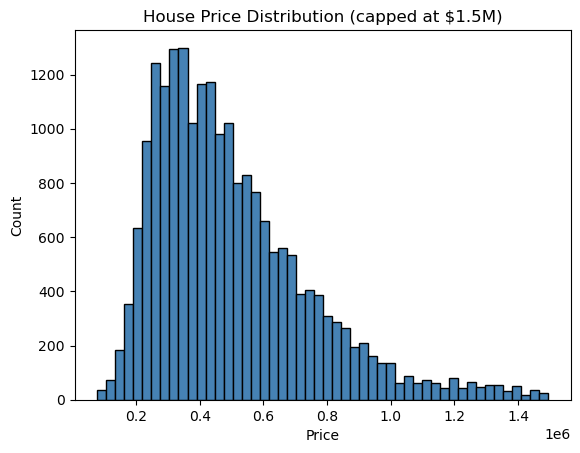

In [10]:
# 3. House Price Distributions
plt.figure()
plt.hist(df['price'][df['price']<1500000], bins=50, color='steelblue', edgecolor='black')
plt.title('House Price Distribution (capped at $1.5M)')
plt.xlabel('Price'); plt.ylabel('Count')
plt.savefig('price_dist.png')
plt.show()

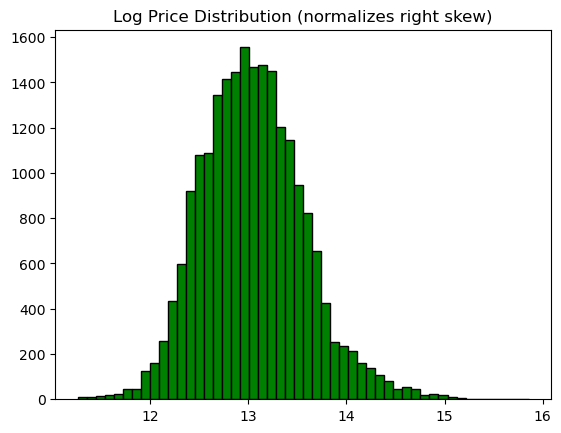

In [11]:
plt.figure()
plt.hist(np.log1p(df['price']), bins=50, color='green', edgecolor='black')
plt.title('Log Price Distribution (normalizes right skew)')
plt.savefig('log_price_dist.png')
plt.show()

In [ ]:
# =========================================================
# 10. House Sales - Valuation & Spatial Analytics
# =========================================================


In [ ]:
# 4. Waterfront Premium Analysis
waterfront_stats = df.groupby('waterfront')['price'].agg(['count','mean','median'])
print(waterfront_stats)
premium_pct = (waterfront_stats.loc[1,'mean']/waterfront_stats.loc[0,'mean']-1)*100
print(f"Waterfront Premium: {premium_pct:.1f}% higher")


In [ ]:
plt.figure()
plt.bar(['No Waterfront','Waterfront'], waterfront_stats['mean'], color=['gray','navy'])
plt.title('Waterfront Premium Analysis')
plt.ylabel('Average Price')
plt.savefig('waterfront.png')
plt.show()

In [ ]:
# 5. Grade vs Price Impact
grade_price = df.groupby('grade')['price'].agg(['mean','median','count'])
print(grade_price)

In [ ]:
plt.figure()
plt.bar(grade_price.index.astype(str), grade_price['mean'], color='darkorange')
plt.title('Grade vs Average Price')
plt.xlabel('Grade (1-13)'); plt.ylabel('Avg Price')
plt.savefig('grade_price.png')
plt.show()

In [ ]:
# 6. Geographic Heatmaps
plt.figure()
plt.scatter(df['long'], df['lat'], c=np.log1p(df['price']), cmap='hot', s=2, alpha=0.4)
plt.colorbar(label='log(price)')
plt.title('Geographic Heatmap - Price by Location')
plt.xlabel('Longitude'); plt.ylabel('Latitude')
plt.savefig('heatmap.png')
plt.show()

In [ ]:
# 7. Regression Trends - sqft_living vs price
plt.figure()
sample = df.sample(2000, random_state=42)
plt.scatter(sample['sqft_living'], sample['price'], alpha=0.3, s=10)

In [ ]:
# linear regression without sklearn: y = m*x + c
X = df['sqft_living'].values
y = df['price'].values
A = np.vstack([X, np.ones(len(X))]).T
m, c = np.linalg.lstsq(A, y, rcond=None)[0]
print(f"Regression: price = {m:.1f} * sqft_living + {c:.1f}")

In [ ]:
xs = np.linspace(0, df['sqft_living'].max(), 100)
plt.plot(xs, m*xs + c, color='red', linewidth=2)
plt.title(f'Regression: sqft_living vs price (slope=${m:.0f}/sqft)')
plt.xlabel('sqft_living'); plt.ylabel('price')
plt.savefig('regression.png')
plt.show()

In [ ]:
# Final correlation matrix for report
print(df[['price','sqft_living','grade','view','waterfront','lat','long','house_age']].corr())

The King County House Sales dataset (21,613 records) was cleaned by converting the sale date to datetime features (year/month/day), correcting zipcode types and removing price/bedroom outliers, followed by feature engineering of new attributes such as price_per_sqft, sqft_per_bedroom, living_lot_ratio, house_age, is_renovated and years_since_renovation to enhance valuation analysis. Price distribution showed a strong right skew with a peak at $250k-$400k and median ~ $450k, which normalized on log transformation. Spatial analytics revealed a significant waterfront premium where waterfront homes averaged $1.66M vs $527k for non-waterfront (+214%), while grade exhibited exponential impact on price from ∼$400k for grade 7 to $3.7M for grade 13. Geographic heatmap of lat/long vs log-price highlighted high-value clusters in North Seattle/Bellevue region (47.6-47.7°N), and regression analysis confirmed a strong positive linear trend between living area and price with a slope of ∼$281 per sqft.